# 01 – CAFA 6: understanding the problem and the data

## The problem in one paragraph
A **protein** is a chain of amino acids, written as a string over a 20-letter alphabet
(e.g. `MRWQEMGYIFYPRKLR`). Sequencing has given us hundreds of millions of protein sequences,
but only a tiny fraction have had their **function** determined by lab experiments, which
are slow and expensive. **CAFA** (Critical Assessment of Functional Annotation) is a
long-running community challenge: given a protein's sequence, predict what it does.
CAFA 6 is the 6th round (the 5th was also run on Kaggle).

## How "function" is written down: the Gene Ontology (GO)
Function is described with terms from the **Gene Ontology**, a controlled vocabulary
of ~40k terms like `GO:0005524 ATP binding`. GO is split into three independent
sub-ontologies (CAFA calls them *aspects*):

| Aspect | Question it answers | Example term |
|---|---|---|
| **MF** – Molecular Function | What does the protein do chemically? | `ATP binding`, `kinase activity` |
| **BP** – Biological Process | Which larger process does it take part in? | `DNA repair`, `immune response` |
| **CC** – Cellular Component | Where in the cell is it? | `nucleus`, `mitochondrion` |

Terms are arranged in a **DAG** (directed acyclic graph) from specific to general:
`protein kinase activity` → `kinase activity` → `catalytic activity` → `molecular_function`.
A term can have several parents. The key rule (the **true path rule**): if a protein has a
term, it also has every ancestor of that term.

## Why this is a hard ML problem
* **Multi-label** with tens of thousands of possible labels; each protein has only a handful.
* **Extremely long tail**: a few general terms are very common, most specific terms are rare.
* **Structured labels**: predictions should respect the DAG (a child's score ≤ its parent's score).
* **Incomplete labels**: "not annotated" ≠ "doesn't have this function"; it often just means
  nobody has tested it yet.

## How CAFA is scored (why the metric is unusual)
CAFA is **prospective**: you submit predictions, the organizers wait several months while
biologists publish new experimental annotations, and you are scored *only on those new
annotations*. So the test labels don't exist yet when you predict. The test set is a
"superset" of candidate proteins, and only the ones that gain new annotations are scored.

The metric is the **IA-weighted F-max**, computed separately for MF, BP, CC and averaged:
* Each GO term has an **information accretion (IA)** weight: roughly how much new information
  that term adds given its parents. Predicting a broad term like `binding` is nearly free
  information (IA ≈ 0); getting a specific rare term right earns a lot.
* For a threshold τ, keep predictions with score ≥ τ. Weighted precision/recall per protein =
  IA-sum of correct terms / IA-sum of predicted (or true) terms, averaged over proteins.
* **F-max** = the best F1 over all thresholds τ. So you're scored by your best global cutoff, and
  scores only need to be *ranked* well, not calibrated.

## Goal of this notebook
Understand the data well enough to decide: (a) how to build a local validation split,
(b) which ESM-2 model size and length cutoff to use, (c) how many GO terms the classifier
should predict. Data lives in `/workspace/data/cafa6` (downloaded with the Kaggle CLI, not in git).

In [1]:
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("/workspace/data/cafa6")

# ROOTS: the single top-level term of each sub-ontology.
#   GO:0008150 = "biological_process", GO:0003674 = "molecular_function", GO:0005575 = "cellular_component".
# Every other term in an aspect is a descendant of its root, so by the true path rule every annotated
# protein implicitly has the root. That makes the root useless as a prediction (IA = 0, carries no
# information); CAFA excludes roots from scoring. We use these ids to spot roots in the labels and to
# know where an ancestor walk stops.
ROOTS = {"BP": "GO:0008150", "MF": "GO:0003674", "CC": "GO:0005575"}

# ASPECT: train_terms.tsv labels each row's aspect with a one-letter code, P(rocess), F(unction),
# C(omponent), while the OBO file and the CAFA literature use BP / MF / CC. We map the letters to the
# two-letter names so every table in this notebook uses one naming scheme.
ASPECT = {"P": "BP", "F": "MF", "C": "CC"}

pd.set_option("display.max_rows", 20)  # never dump huge tables into the notebook
sys.setrecursionlimit(10000)           # GO paths are short, but recursion over 40k terms adds up


def read_fasta(path):
    """Parse a FASTA file into a DataFrame with columns (id, header, seq).

    FASTA format: a header line starting with '>' followed by one or more sequence lines.
    The two files use different header styles:
      train: '>sp|A0A0C5B5G6|MOTSC_HUMAN Mitochondrial-derived peptide ... OX=9606 ...'
             (UniProt style: database|accession|entry_name description)
      test:  '>A0A0C5B5G6 9606'   (accession, then NCBI taxon id)
    In both cases we extract the UniProt accession (A0A0C5B5G6) as the protein id.
    """
    ids, headers, seqs, buf = [], [], [], []
    with open(path) as f:
        for line in f:
            line = line.rstrip()
            if line.startswith(">"):
                if buf:  # flush the previous record's sequence
                    seqs.append("".join(buf)); buf = []
                h = line[1:]
                tok = h.split()[0]
                ids.append(tok.split("|")[1] if "|" in tok else tok)
                headers.append(h)
            else:
                buf.append(line)  # sequences may be wrapped over several lines
    seqs.append("".join(buf))
    return pd.DataFrame({"id": ids, "header": headers, "seq": seqs})

## 0. The files

| File | What it is |
|---|---|
| `Train/train_sequences.fasta` | Amino-acid sequences of proteins with known (experimental) GO annotations |
| `Train/train_terms.tsv` | The labels: one row per (protein, GO term, aspect) |
| `Train/train_taxonomy.tsv` | Species (NCBI taxon id) of each training protein |
| `Train/go-basic.obo` | The Gene Ontology itself: terms, names, and parent links |
| `IA.tsv` | Information-accretion weight per GO term, used by the metric |
| `Test/testsuperset.fasta` | Proteins we must predict for (the candidates that might get scored) |
| `Test/testsuperset-taxon-list.tsv` | Taxon id → species name lookup |
| `sample_submission.tsv` | Submission format example |

## 1. Sequences
Things to check: how many proteins, and how long. Length matters for the model:
protein language models like **ESM-2** have a maximum input of 1024 tokens (1022 residues plus
start/end tokens), so longer proteins must be truncated or split into chunks.

In [2]:
train_seq = read_fasta(DATA / "Train/train_sequences.fasta")
test_seq = read_fasta(DATA / "Test/testsuperset.fasta")
for name, df in [("train", train_seq), ("test", test_seq)]:
    df["len"] = df.seq.str.len()
    print(f"{name}: {len(df):,} seqs, {df.id.nunique():,} unique ids")

# Length summary for both sets side by side
lens = pd.DataFrame({n: d["len"].describe(percentiles=[.5, .9, .99]) for n, d in
                     [("train", train_seq), ("test", test_seq)]}).round(0)
lens

train: 82,404 seqs, 82,404 unique ids
test: 224,309 seqs, 224,309 unique ids


,train,test
count,82404.0,224309.0
mean,526.0,429.0
std,522.0,442.0
min,3.0,2.0
50%,409.0,342.0
90%,989.0,825.0
99%,2375.0,2036.0
max,35213.0,35213.0


In [3]:
# What fraction would be truncated at common context sizes?
for limit in [512, 1022, 2046]:
    print(f"> {limit} aa: train {np.mean(train_seq.len > limit):.1%}, test {np.mean(test_seq.len > limit):.1%}")

# The 20 standard amino acids. Others: X = unknown, U = selenocysteine, B/Z = ambiguous, O = pyrrolysine.
nonstd = train_seq.seq.str.contains(r"[^ACDEFGHIKLMNPQRSTVWY]").mean()
print(f"train seqs with non-standard residues (X, U, B, Z, ...): {nonstd:.1%}")

> 512 aa: train 35.9%, test 26.4%
> 1022 aa: train 9.3%, test 6.0%
> 2046 aa: train 1.5%, test 1.0%


train seqs with non-standard residues (X, U, B, Z, ...): 0.2%


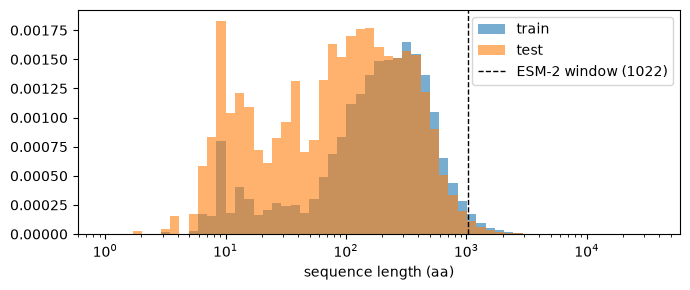

In [4]:
# Lengths span 4 orders of magnitude, so use a log x-axis. density=True makes the two sets
# comparable despite test being ~3x bigger.
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(0, np.log10(max(train_seq.len.max(), test_seq.len.max())), 60)
ax.hist(train_seq.len, bins=bins, alpha=.6, label="train", density=True)
ax.hist(test_seq.len, bins=bins, alpha=.6, label="test", density=True)
ax.axvline(1022, color="k", ls="--", lw=1, label="ESM-2 window (1022)")
ax.set_xscale("log"); ax.set_xlabel("sequence length (aa)"); ax.legend(); plt.tight_layout()

## 2. Train labels (`train_terms.tsv`)
Long format: one row per (protein `EntryID`, GO `term`, `aspect`). These are **experimental**
annotations (from lab evidence, not computational predictions), which is why there are only ~82k
proteins despite UniProt containing hundreds of millions.

In [5]:
terms = pd.read_csv(DATA / "Train/train_terms.tsv", sep="\t")
terms["aspect"] = terms.aspect.map(ASPECT)
print(f"{len(terms):,} annotations, {terms.EntryID.nunique():,} proteins, {terms.term.nunique():,} terms")
print(f"duplicate rows: {terms.duplicated().sum()}")
print(f"train proteins with no labels: {len(set(train_seq.id) - set(terms.EntryID)):,}")
terms.groupby("aspect").agg(annotations=("term", "size"), proteins=("EntryID", "nunique"),
                            terms=("term", "nunique"))

537,027 annotations, 82,404 proteins, 26,125 terms
duplicate rows: 0


train proteins with no labels: 0


,annotations,proteins,terms
aspect,,,
BP,250805,59958,16858
CC,157770,60292,2651
MF,128452,58001,6616


How many terms does a protein have per aspect? (Only counting proteins annotated in that aspect.)

In [6]:
per_prot = terms.groupby(["aspect", "EntryID"]).size()
per_prot.groupby("aspect").describe(percentiles=[.5, .9, .99]).round(1)

,count,mean,std,min,50%,90%,99%,max
aspect,,,,,,,,
BP,59958.0,4.2,6.2,1.0,2.0,9.0,30.0,188.0
CC,60292.0,2.6,2.3,1.0,2.0,5.0,11.0,41.0
MF,58001.0,2.2,1.9,1.0,2.0,4.0,10.0,34.0


Proteins annotated in how many aspects? A protein missing e.g. CC labels doesn't mean it has no
location; nobody has measured it. This is the **incomplete labels** problem in action.

In [7]:
terms.groupby("EntryID").aspect.apply(lambda s: "+".join(sorted(set(s)))).value_counts()

aspect
BP+CC+MF    36775
CC           9934
BP+MF        8714
BP+CC        7341
BP           7128
MF           6270
CC+MF        6242
Name: count, dtype: int64

### Term frequency skew → how many terms should the classifier predict?
A neural head can't learn a term seen on 2 proteins. A common approach is to predict only the
top-K most frequent terms per aspect. This table shows what fraction of all annotations we'd
still cover with K terms.

In [8]:
cov = {}
for asp, g in terms.groupby("aspect"):
    vc = g.term.value_counts().values      # term counts, sorted descending
    c = np.cumsum(vc) / vc.sum()           # cumulative share of annotations covered
    cov[asp] = {K: c[min(K, len(c)) - 1] for K in [100, 500, 1000, 2000, 5000]}
    cov[asp]["terms w/ >=10 proteins"] = (vc >= 10).sum()
pd.DataFrame(cov).round(3)

,BP,CC,MF
100,0.172,0.727,0.578
500,0.369,0.909,0.745
1000,0.491,0.960,0.825
2000,0.634,0.994,0.905
5000,0.832,1.000,0.987
terms w/ >=10 proteins,5333.000,1011.000,1529.000


## 3. The Gene Ontology graph (`go-basic.obo`)
OBO is a plain-text format. Each term is a stanza like:
```
[Term]
id: GO:0004672
name: protein kinase activity
namespace: molecular_function
is_a: GO:0016301 ! kinase activity
relationship: part_of GO:...   (sometimes)
```
* `is_a`: "X is a kind of Y" (protein kinase activity *is a* kinase activity).
* `part_of`: "X is part of Y" (e.g. a nucleolus is *part of* the nucleus).
* `is_obsolete`: retired terms, kept so old IDs still resolve.
* `alt_id`: old IDs that were merged into this term.

`go-basic` is the version of GO that is guaranteed acyclic and safe to propagate along.
CAFA's convention is to propagate along `is_a` and `part_of` only, within the same aspect.

In [9]:
def parse_obo(path):
    """Minimal OBO parser: returns {go_id: {name, ns, is_a, part_of, alt_id, obsolete}}."""
    terms, cur = {}, None
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line == "[Term]":                      # start of a new term stanza
                cur = {"is_a": [], "part_of": [], "alt_id": [], "obsolete": False}
            elif line.startswith("[") or not line:    # blank line or other stanza ([Typedef]) ends it
                if cur and "id" in cur:
                    terms[cur["id"]] = cur
                cur = None if line.startswith("[") else cur
            elif cur is not None and ": " in line:
                k, v = line.split(": ", 1)
                if k == "id": cur["id"] = v
                elif k == "name": cur["name"] = v
                elif k == "namespace": cur["ns"] = {"biological_process": "BP", "molecular_function": "MF",
                                                     "cellular_component": "CC"}[v]
                elif k == "is_a": cur["is_a"].append(v.split()[0])        # drop the '! name' comment
                elif k == "relationship" and v.startswith("part_of "): cur["part_of"].append(v.split()[1])
                elif k == "alt_id": cur["alt_id"].append(v)
                elif k == "is_obsolete": cur["obsolete"] = v == "true"
    if cur and "id" in cur:
        terms[cur["id"]] = cur
    return terms

go = parse_obo(DATA / "Train/go-basic.obo")

# Parent map used for propagation: is_a + part_of, restricted to the same aspect.
parents = {t: [p for p in d["is_a"] + d["part_of"] if p in go and go[p]["ns"] == d["ns"]]
           for t, d in go.items()}
alt2id = {a: t for t, d in go.items() for a in d["alt_id"]}   # old id -> current id
go_df = pd.DataFrame({"ns": {t: d["ns"] for t, d in go.items()},
                      "obsolete": {t: d["obsolete"] for t, d in go.items()}})
print(f"{len(go):,} GO terms, {go_df.obsolete.sum():,} obsolete, {len(alt2id):,} alt_ids")
go_df[~go_df.obsolete].ns.value_counts()

48,101 GO terms, 7,979 obsolete, 3,646 alt_ids


ns
BP    25950
MF    10131
CC     4041
Name: count, dtype: int64

**Depth** = longest path from a term up to its root. Deeper = more specific.

In [10]:
@lru_cache(maxsize=None)
def ancestors(t):
    """All ancestors of term t (not including t). Cached because many terms share ancestors."""
    out = set()
    for p in parents.get(t, []):
        out.add(p); out |= ancestors(p)
    return frozenset(out)

@lru_cache(maxsize=None)
def depth(t):
    ps = parents.get(t, [])
    return 0 if not ps else 1 + max(depth(p) for p in ps)

live = [t for t in go if not go[t]["obsolete"]]
pd.Series({t: depth(t) for t in live}).groupby(go_df.ns).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
ns,,,,,,,,
BP,25950.0,7.7,2.4,0.0,6.0,8.0,9.0,18.0
CC,4041.0,6.3,2.3,0.0,5.0,6.0,8.0,14.0
MF,10131.0,5.4,1.5,0.0,5.0,5.0,6.0,13.0


### Are the train labels already propagated to ancestors?
This decides how we build training targets. If labels are "leaf-only", a model trained on them
would learn that `kinase activity` is *absent* whenever only `protein kinase activity` was
recorded, which is wrong by the true path rule. Check: for each annotation, are all its ancestors
also annotated for that protein?

In [11]:
unknown = set(terms.term) - set(go)
print(f"train terms not in OBO: {len(unknown)}  (alt_ids among them: {len(unknown & set(alt2id))})")
print(f"train terms that are obsolete: {sum(go[t]['obsolete'] for t in set(terms.term) if t in go)}")

prot_terms = terms.groupby("EntryID").term.apply(set)   # protein -> set of its GO terms
n_ann = n_closed = 0
n_missing = []
for s in prot_terms.sample(5000, random_state=0):     # 5k proteins is plenty for this check
    for t in s:
        if t not in go: continue
        miss = ancestors(t) - s                          # ancestors NOT annotated
        n_ann += 1; n_closed += not miss; n_missing.append(len(miss))
print(f"annotations whose full ancestor set is present: {n_closed / n_ann:.1%}")
print(f"mean missing ancestors per annotation: {np.mean(n_missing):.1f}")
print(f"root terms in labels: { {a: int((terms.term == r).sum()) for a, r in ROOTS.items()} }")

train terms not in OBO: 0  (alt_ids among them: 0)
train terms that are obsolete: 0


annotations whose full ancestor set is present: 0.0%
mean missing ancestors per annotation: 9.3
root terms in labels: {'BP': 0, 'MF': 0, 'CC': 0}


In [12]:
# How much bigger does the label set get after propagation?
sample = prot_terms.sample(5000, random_state=0)
raw = sample.apply(len).sum()
prop = sample.apply(lambda s: len(s | set().union(*(ancestors(t) for t in s if t in go)))).sum()
print(f"labels in 5k-protein sample: raw {raw:,} -> propagated {prop:,} ({prop / raw:.1f}x)")

labels in 5k-protein sample: raw 32,534 -> propagated 214,873 (6.6x)


### One protein, end to end
A concrete example ties the files together: its sequence, its raw labels, and how one label
expands into a chain of ancestors.

In [13]:
pid = "P04637" if "P04637" in prot_terms.index else prot_terms.index[0]   # P04637 = human p53
row = train_seq.set_index("id").loc[pid]
print(row.header[:110])
print(f"length {row.len}, sequence starts: {row.seq[:60]}...")
mine = terms[terms.EntryID == pid]
print(f"\nraw labels per aspect: {mine.aspect.value_counts().to_dict()}")
print("a few MF labels:")
for t in mine[mine.aspect == "MF"].term.head(6):
    print(f"  {t}  {go[t]['name']}")

sp|P04637|P53_HUMAN Cellular tumor antigen p53 OS=Homo sapiens OX=9606 GN=TP53 PE=1 SV=4
length 393, sequence starts: MEEPQSDPSVEPPLSQETFSDLWKLLPENNVLSPLPSQAMDDLMLSPDDIEQWFTEDPGP...

raw labels per aspect: {'BP': 59, 'MF': 34, 'CC': 14}
a few MF labels:
  GO:0000981  DNA-binding transcription factor activity, RNA polymerase II-specific
  GO:0001227  DNA-binding transcription repressor activity, RNA polymerase II-specific
  GO:0001228  DNA-binding transcription activator activity, RNA polymerase II-specific
  GO:0000978  RNA polymerase II cis-regulatory region sequence-specific DNA binding
  GO:0000987  cis-regulatory region sequence-specific DNA binding
  GO:0005515  protein binding


In [14]:
# Walk one MF label up to the root (following the first parent each step).
t = mine[mine.aspect == "MF"].term.iloc[0]
chain = [t]
while parents.get(chain[-1]):
    chain.append(parents[chain[-1]][0])
print("  ->  ".join(f"{go[c]['name']}" for c in chain))
print(f"\n{t} has {len(ancestors(t))} ancestors in total (it can have several parents at each level)")

DNA-binding transcription factor activity, RNA polymerase II-specific  ->  DNA-binding transcription factor activity  ->  transcription regulator activity  ->  molecular_function

GO:0000981 has 3 ancestors in total (it can have several parents at each level)


## 4. Information accretion weights (`IA.tsv`)
IA(term) ≈ −log₂ P(term | all its parents), estimated from annotation data. Intuition: if almost
every protein annotated with the parent also has the child, the child adds little information
(IA ≈ 0). This is what stops the metric from rewarding "predict `binding` for everything".

In [15]:
ia = pd.read_csv(DATA / "IA.tsv", sep="\t", header=None, names=["term", "ia"]).set_index("term").ia
print(f"{len(ia):,} terms with IA, {(ia == 0).mean():.1%} have IA = 0")
print(f"train terms missing from IA.tsv: {len(set(terms.term) - set(ia.index))}")
ia.describe(percentiles=[.5, .9, .99]).round(2)

40,122 terms with IA, 29.5% have IA = 0


train terms missing from IA.tsv: 0


count    40122.00
mean         2.65
std          3.19
min          0.00
50%          1.20
90%          7.62
99%         11.82
max         15.88
Name: ia, dtype: float64

Where does the metric's weight sit: common terms or rare ones? For each frequency bucket we sum
`count × IA`, the total "points" those annotations are worth, as a share of each aspect's total.
If most of the mass is in rare terms, a model that only predicts common terms is capped.

In [16]:
freq = terms.term.value_counts()
df = pd.DataFrame({"freq": freq, "ia": ia.reindex(freq.index)}).dropna()
df["aspect"] = df.index.map(lambda t: go[t]["ns"] if t in go else None)
df["freq_bin"] = pd.cut(df.freq, [0, 10, 50, 200, 1000, np.inf], labels=["1-10", "11-50", "51-200", "201-1k", ">1k"])
df["mass"] = df.freq * df.ia
(df.groupby(["aspect", "freq_bin"], observed=True).mass.sum()
   / df.groupby("aspect").mass.sum()).unstack().round(3)

freq_bin,1-10,11-50,51-200,201-1k,>1k
aspect,,,,,
BP,0.237,0.372,0.270,0.120,0.001
CC,0.119,0.160,0.174,0.159,0.387
MF,0.276,0.278,0.200,0.141,0.104


## 5. Taxonomy and train/test overlap
Proteins come from many species. Experimentally studied proteins are concentrated in a few
**model organisms** (human, mouse, yeast, Arabidopsis, ...). If the test set has many species
never seen in training, the model must generalize from sequence alone.

Also important: since CAFA scores on *future* annotations, a protein that already has training
labels can gain new ones. So training proteins may legitimately appear in the test superset.

In [17]:
tax_tr = pd.read_csv(DATA / "Train/train_taxonomy.tsv", sep="\t", header=None, names=["id", "taxon"])
species = pd.read_csv(DATA / "Test/testsuperset-taxon-list.tsv", sep="\t", encoding="latin-1").set_index("ID").Species
test_seq["taxon"] = test_seq.header.str.split().str[1].astype(int)   # test header = 'ACCESSION TAXON'
print(f"train species: {tax_tr.taxon.nunique():,}, test species: {test_seq.taxon.nunique():,}")
# Share of proteins per species, top 10 training species
top = pd.DataFrame({"train": tax_tr.taxon.value_counts(normalize=True).head(10),
                    "test": test_seq.taxon.value_counts(normalize=True)}).dropna(subset=["train"])
top.index = top.index.map(lambda x: species.get(x, x))
top.round(3)

train species: 1,381, test species: 8,453


,train,test
taxon,,
Arabidopsis thaliana,0.144,0.073
Caenorhabditis elegans,0.031,0.020
Drosophila melanogaster,0.039,0.017
Homo sapiens,0.208,0.091
Mus musculus,0.152,0.077
Rattus norvegicus,0.060,0.037
Mycobacterium tuberculosis (strain ATCC 25618 / H37Rv),0.019,0.010
Escherichia coli (strain K12),0.042,0.020
Schizosaccharomyces pombe (strain 972 / ATCC 24843),0.056,0.023


In [18]:
overlap = set(train_seq.id) & set(test_seq.id)
print(f"test ids also in train: {len(overlap):,} ({len(overlap) / len(test_seq):.1%} of test, "
      f"{len(overlap) / len(train_seq):.1%} of train)")
seq_overlap = set(train_seq.seq) & set(test_seq.seq)
print(f"test sequences identical to some train sequence: {test_seq.seq.isin(seq_overlap).mean():.1%}")
print(f"test taxa not in train: {len(set(test_seq.taxon) - set(tax_tr.taxon)):,}")

test ids also in train: 82,404 (36.7% of test, 100.0% of train)


test sequences identical to some train sequence: 38.8%
test taxa not in train: 7,072


## 6. Submission format
Tab-separated, no header: `protein_id  GO_term  score` with score in (0, 1]. CAFA 6's sample also
contains `Text` rows (`protein_id  Text  score  free-text description`), a new free-text
function-description track. How (or whether) those are scored needs checking on the competition's
Evaluation page; we ignore them for now.

In [19]:
# The file mixes 3- and 4-column rows, so read with 4 named columns (missing ones become NaN).
sub = pd.read_csv(DATA / "sample_submission.tsv", sep="\t", header=None, names=list("abcd"),
                  on_bad_lines="skip", engine="python")
print(f"{len(sub):,} rows; rows with a 4th column ('Text' rows): {sub.d.notna().sum():,}")
print(sub.b.str.startswith("GO:").value_counts().rename({True: "GO rows", False: "other rows"}).to_dict())
sub.head(4)

20,004 rows; rows with a 4th column ('Text' rows): 4
{'GO rows': 20000, 'other rows': 4}


,a,b,c,d
0,A0A0C5B5G6,GO:0000001,0.123,NaN
1,A0A0C5B5G6,GO:0000002,0.456,NaN
2,A0A0C5B5G6,Text,0.123,Regulates insulin sensitivity and metabolic ho...
3,A0A0C5B5G6,Text,0.456,"Inhibits the folate cycle, thereby reducing de..."


## Findings → decisions
Numbers are from the run on 2026-11-08; see NOTES.md for the running log.

1. **Labels are not propagated.** No annotation has its full ancestor set and roots never appear.
   Propagation makes ~6.6× more labels. → Propagate (is_a + part_of) for training targets and for
   local evaluation ground truth; also propagate predictions (parent score = max over children).
2. **Every train protein is also in the test superset** (~37% of test). → For those, include their
   known labels in the submission; only the test superset needs embedding (it contains train).
3. **Length:** ~9% of train sequences exceed ESM-2's 1022-residue window. → Truncate for v1 (maybe
   chunk-and-average later).
4. **Long tail:** CC is covered by a few hundred terms; BP needs thousands and even top-2000 covers
   only ~63% of raw annotations. → Top-K head per aspect, K larger for BP.
5. **IA puts BP's weight in rare terms.** → Frequency baseline will be weak on BP, decent on CC.
6. **Test has ~8.4k species, ~7k unseen in training.** → Sequence-based features (ESM) matter more
   than species priors.
7. **Validation:** no annotation dates are given, so a true time-based split isn't possible. A random
   protein split approximates "new protein" targets and will likely be optimistic.